# 06 — Gradient Boosting para Previsão de Séries Temporais

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE1 + OE2 — Modelos baseados em árvores de decisão

---
### GBT vs Random Forest — diferença fundamental

| Aspecto | Random Forest | Gradient Boosting |
|---|---|---|
| Estratégia | Paralela (bagging) | Sequencial (boosting) |
| Cada árvore | Independente | Corrige erros da anterior |
| Viés/variância | Reduz variância | Reduz viés |
| Overfitting | Menos suscetível | Mais suscetível — controla via learning_rate |
| Velocidade treino | Mais rápido (paralelo) | Mais lento (sequencial) |

### Engenharia de features
**Idêntica ao notebook 05** — mesmos lags, roll_mean, roll_std e lags sazonais.  
Isso garante **comparação justa** entre RF e GBT dentro da família de árvores (seção 5.2).

### Hiperparâmetros principais
- `n_estimators`: número de árvores sequenciais
- `learning_rate`: tamanho do passo de correção (α)
- `max_depth`: profundidade máxima de cada árvore — GBT usa árvores rasas
- `subsample`: fração de amostras por árvore — reduz overfitting

## 1. Imports e configurações

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import json
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import GradientBoostingRegressor

warnings.filterwarnings('ignore')

import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'config.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.config import (
    DATA_DIR,
    H,
    MIN_TRAIN,
    N_ORIGINS,
    PILOT_N,
    PROJECT_ROOT,
    RESULT_DIR,
    SEASON,
    SEED,
    verify_data_files,
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)
verify_data_files()
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR       = {DATA_DIR}  OK')
print(f'RESULT_DIR     = {RESULT_DIR}')

# ── Configuração do GBT ───────────────────────────────────────────────────────
# Idêntica ao RF onde possível para comparação justa
N_LAGS        = 12     # mesmo do RF
N_ESTIMATORS  = 100    # mesmo número de árvores
LEARNING_RATE = 0.1    # passo de correção
MAX_DEPTH     = 3      # árvores rasas — padrão para GBT
SUBSAMPLE     = 0.8    # 80% das amostras por árvore

np.random.seed(SEED)
print('Configuração carregada OK')
print(f'  Lags          : {N_LAGS}')
print(f'  n_estimators  : {N_ESTIMATORS}')
print(f'  learning_rate : {LEARNING_RATE}')
print(f'  max_depth     : {MAX_DEPTH}')
print(f'  subsample     : {SUBSAMPLE}')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
DATA_DIR       = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw  OK
RESULT_DIR     = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results
Configuração carregada OK
  Lags          : 12
  n_estimators  : 100
  learning_rate : 0.1
  max_depth     : 3
  subsample     : 0.8


## 2. Funções base (pipeline padrão)

In [2]:
from src.m4_io import load_m4_monthly, sample_pilot_ids

def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]

def calc_mape(y_true, y_pred):
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }

print('Funções base OK')

Funções base OK


## 3. Carregamento e piloto

In [3]:
import sys
from pathlib import Path

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'config.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.config import DATA_DIR, PILOT_N, SEED
from src.m4_io import load_m4_monthly, sample_pilot_ids

pilot_ids = sample_pilot_ids(DATA_DIR, PILOT_N, SEED)
train_df, test_df = load_m4_monthly(DATA_DIR, series_ids=pilot_ids)
train_pilot = train_df.copy()
print(f'Piloto: {PILOT_N} séries | {len(train_pilot):,} linhas train | {len(test_df):,} linhas test')

Piloto: 200 séries | 42,600 linhas train | 3,600 linhas test


## 4. Engenharia de features (idêntica ao RF)

Mesma função do notebook 05 — garante comparação justa entre RF e GBT.

In [6]:
def build_features(series, n_lags=N_LAGS, season=SEASON):
    """
    Idêntica ao notebook 05.
    Features: lag_1..lag_L, roll_mean, roll_std, lag_season, lag_season2
    """
    n      = len(series)
    lag_cols = {f'lag_{i}': np.full(n, np.nan) for i in range(1, n_lags+1)}
    for i in range(1, n_lags+1):
        lag_cols[f'lag_{i}'][i:] = series[:-i]

    df = pd.DataFrame(lag_cols)
    df['roll_mean'] = df[[f'lag_{i}' for i in range(1, n_lags+1)]].mean(axis=1)
    df['roll_std']  = df[[f'lag_{i}' for i in range(1, n_lags+1)]].std(axis=1)
    df['lag_season']  = np.nan
    df['lag_season2'] = np.nan
    if n > season:
        df.loc[season:, 'lag_season'] = series[:-season]
    if n > 2*season:
        df.loc[2*season:, 'lag_season2'] = series[:-2*season]
    df['y'] = series

    feature_cols = [f'lag_{i}' for i in range(1, n_lags + 1)] + [
        'roll_mean', 'roll_std', 'lag_season',
    ]
    if n > 2 * season:
        feature_cols.append('lag_season2')

    df = df.dropna(subset=feature_cols)
    return df[feature_cols].values, df['y'].values, feature_cols


def predict_recursive(model, train, horizon, n_lags=N_LAGS, season=SEASON,
                      feature_cols=None):
    """Previsão recursiva multi-passo — alinhada às colunas de build_features."""
    if feature_cols is None:
        _, _, feature_cols = build_features(train, n_lags, season)

    use_lag2 = 'lag_season2' in feature_cols
    history = list(train.copy())
    preds   = []

    for _ in range(horizon):
        n = len(history)
        lags = [history[n - i] for i in range(1, n_lags + 1)]
        roll_mean = float(np.mean(lags))
        roll_std  = float(np.std(lags, ddof=1)) if len(lags) > 1 else 0.0
        lag_s = history[n - season] if n >= season else history[0]

        feats = lags + [roll_mean, roll_std, lag_s]
        if use_lag2:
            lag_s2 = history[n - 2 * season] if n >= 2 * season else history[0]
            feats.append(lag_s2)

        x = np.array(feats, dtype=float).reshape(1, -1)
        pred = model.predict(x)[0]
        preds.append(pred)
        history.append(pred)

    return np.array(preds)


# Verificação rápida
ex = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 3).astype(float)
X_ex, y_ex, feat_names = build_features(ex)
print(f'Série {len(ex)} obs → {X_ex.shape[0]} amostras | {len(feat_names)} features')
print('Features OK — idênticas ao RF')

Série 36 obs → 12 amostras | 16 features
Features OK — idênticas ao RF


## 5. Modelo Gradient Boosting

In [7]:
def model_gbt(train, horizon,
              n_lags=N_LAGS, season=SEASON,
              n_estimators=N_ESTIMATORS,
              learning_rate=LEARNING_RATE,
              max_depth=MAX_DEPTH,
              subsample=SUBSAMPLE):
    """
    Gradient Boosting para previsão de séries temporais.
    Mesma interface do RF: train → H previsões recursivas.
    """
    min_needed = max(n_lags, season) + 1
    if len(train) < min_needed:
        return np.full(horizon, np.mean(train))

    X, y, feat_cols = build_features(train, n_lags, season)
    if len(X) < 2:
        return np.full(horizon, np.mean(train))

    gbt = GradientBoostingRegressor(
        n_estimators  = n_estimators,
        learning_rate = learning_rate,
        max_depth     = max_depth,
        subsample     = subsample,
        random_state  = SEED
        # GBT não suporta n_jobs — é inerentemente sequencial
    )
    gbt.fit(X, y)
    return predict_recursive(
        gbt, train, horizon, n_lags, season, feature_cols=feat_cols
    )


# Verificação
ex_pred = model_gbt(ex, horizon=H)
print(f'GBT — previsão {H} passos: {ex_pred.round(1)}')
print(f'Constante? {np.allclose(ex_pred, ex_pred[0])}')

GBT — previsão 18 passos: [100.  105.  110.  115.  120.  125.  120.  115.  110.  104.6 100.   95.
 100.  106.3 110.  114.7 120.  125. ]
Constante? False


## 6. Execução do pipeline

> **Tempo esperado**: 5–15 minutos.  
> GBT é sequencial (sem `n_jobs`) — mais lento que RF para o mesmo número de árvores.

In [8]:
def run_pipeline(train_df, horizon, min_train, n_origins, model_name, predict_fn):
    records = []
    ids     = train_df['unique_id'].unique()
    total   = len(ids)
    for i, uid in enumerate(ids):
        if (i+1) % 50 == 0 or i == 0:
            print(f'  [{i+1}/{total}] {uid}')
        values  = train_df[train_df['unique_id']==uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)
        if not windows:
            records.append({'unique_id':uid,'model':model_name,'origin':None,
                            'n_train':None,'mape':None,'mae':None,'r2':None,
                            'exec_time_s':None,'status':'SKIP_SHORT'})
            continue
        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape':None,'mae':None,'r2':None}
                status  = f'ERROR: {str(e)[:80]}'
            records.append({
                'unique_id'  : uid, 'model': model_name,
                'origin'     : win['origin'], 'n_train': len(win['train']),
                **metrics,
                'exec_time_s': time.perf_counter()-t0,
                'status'     : status
            })
    return pd.DataFrame(records)


print(f'Rodando Gradient Boosting em {PILOT_N} séries...')
t_start = time.time()

results_gbt = run_pipeline(
    train_df   = train_pilot,
    horizon    = H,
    min_train  = MIN_TRAIN,
    n_origins  = N_ORIGINS,
    model_name = 'gbt',
    predict_fn = model_gbt
)

elapsed = time.time() - t_start
ok_n    = (results_gbt['status'] == 'OK').sum()
err_n   = results_gbt['status'].str.startswith('ERROR', na=False).sum()
skip_n  = (results_gbt['status'] == 'SKIP_SHORT').sum()

print(f'\nConcluído em {elapsed:.1f}s ({elapsed/60:.1f} min)')
print(f'  OK           : {ok_n} janelas')
print(f'  Erros        : {err_n}')
print(f'  Taxa sucesso : {100*ok_n/(ok_n+err_n+skip_n):.1f}%')

Rodando Gradient Boosting em 200 séries...
  [1/200] M10288
  [50/200] M21209
  [100/200] M32071
  [150/200] M40980
  [200/200] M9633

Concluído em 31.0s (0.5 min)
  OK           : 600 janelas
  Erros        : 0
  Taxa sucesso : 100.0%


## 7. Resultados e comparação acumulada

In [9]:
ok_gbt = results_gbt[results_gbt['status'] == 'OK'].copy()

by_series_gbt = (
    ok_gbt.groupby('unique_id')[['mape','mae','r2','exec_time_s']]
    .median().reset_index()
)

print('=== Desempenho Gradient Boosting ===')
print(by_series_gbt[['mape','mae','r2']].describe().round(3).to_string())
print(f'\nMAPE mediano = {by_series_gbt["mape"].median():.4f}%')
print(f'MAE  mediano = {by_series_gbt["mae"].median():.4f}')
print(f'R²   mediano = {by_series_gbt["r2"].median():.4f}')
print(f'Tempo mediano= {by_series_gbt["exec_time_s"].median():.4f}s')

# Tabela acumulada
prev_path = RESULT_DIR / 'tabela_acumulada_nb05_rf.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0)
    gbt_row = pd.DataFrame([{
        'MAPE (%)' : round(by_series_gbt['mape'].median(), 4),
        'MAE'      : round(by_series_gbt['mae'].median(),  4),
        'R²'       : round(by_series_gbt['r2'].median(),   4),
        'Tempo (s)': round(by_series_gbt['exec_time_s'].median(), 4),
    }], index=['Gradient Boosting'])
    summary = pd.concat([prev, gbt_row]).sort_values('MAPE (%)')
else:
    summary = pd.DataFrame([{
        'MAPE (%)' : round(by_series_gbt['mape'].median(), 4),
        'MAE'      : round(by_series_gbt['mae'].median(),  4),
        'R²'       : round(by_series_gbt['r2'].median(),   4),
        'Tempo (s)': round(by_series_gbt['exec_time_s'].median(), 4),
    }], index=['Gradient Boosting'])

print('\n=== Comparação acumulada ===')
print(summary.to_string())
summary.to_csv(RESULT_DIR / 'tabela_acumulada_nb06_gbt.csv')
print('\nTabela salva em results/tabela_acumulada_nb06_gbt.csv')

=== Desempenho Gradient Boosting ===
          mape       mae       r2
count  200.000   200.000  200.000
mean    16.084   628.524   -1.748
std     20.942   943.956    2.003
min      0.697    11.406  -14.351
25%      3.877   141.078   -2.570
50%      9.903   321.677   -1.184
75%     20.503   720.723   -0.305
max    165.134  6747.943    0.955

MAPE mediano = 9.9031%
MAE  mediano = 321.6768
R²   mediano = -1.1837
Tempo mediano= 0.0477s

=== Comparação acumulada ===
                   MAPE (%)       MAE      R²  Tempo (s)
Holt-Winters         8.2606  256.0183 -1.0642     0.1852
Persistência         8.6992  274.1667 -1.2684     0.0004
SES                  8.7764  253.5196 -1.1898     0.0038
SARIMA auto (AIC)    9.1184  266.3902 -1.2678     0.2127
Gradient Boosting    9.9031  321.6768 -1.1837     0.0477
SARIMA heurístico   10.0628  284.7858 -2.0551     0.0990
Random Forest       10.5861  341.6680 -1.0925     0.3364
Sazonal ingênuo     11.0601  316.8889 -2.1744     0.0004
Média histórica     

## 8. Comparação direta RF vs GBT

Comparação dentro da família de árvores — dado direto para a seção 2.3 da dissertação.

In [10]:
rf_path = RESULT_DIR / 'results_rf_by_series.csv'

if rf_path.exists():
    rf_df = pd.read_csv(rf_path)

    comp_arvores = pd.DataFrame({
        'Random Forest'     : [
            rf_df['mape'].median(),
            rf_df['mae'].median(),
            rf_df['r2'].median(),
            rf_df['exec_time_s'].median()
        ],
        'Gradient Boosting' : [
            by_series_gbt['mape'].median(),
            by_series_gbt['mae'].median(),
            by_series_gbt['r2'].median(),
            by_series_gbt['exec_time_s'].median()
        ]
    }, index=['MAPE (%)', 'MAE', 'R²', 'Tempo (s)'])

    comp_arvores['Diferença (%)'] = (
        (comp_arvores['Gradient Boosting'] - comp_arvores['Random Forest'])
        / comp_arvores['Random Forest'].abs() * 100
    ).round(2)

    print('=== Comparação dentro da família de árvores ===')
    print(comp_arvores.round(4).to_string())
    comp_arvores.to_csv(RESULT_DIR / 'comparacao_rf_vs_gbt.csv')

    # Por série — GBT melhor que RF em quantas?
    merged = rf_df[['unique_id','mape']].rename(columns={'mape':'mape_rf'}).merge(
        by_series_gbt[['unique_id','mape']].rename(columns={'mape':'mape_gbt'}),
        on='unique_id'
    )
    gbt_melhor = (merged['mape_gbt'] < merged['mape_rf']).mean() * 100
    print(f'\nGBT melhor que RF em {gbt_melhor:.1f}% das séries')
    print(f'RF  melhor que GBT em {100-gbt_melhor:.1f}% das séries')
else:
    print('Arquivo RF não encontrado. Execute o notebook 05 primeiro.')

=== Comparação dentro da família de árvores ===
           Random Forest  Gradient Boosting  Diferença (%)
MAPE (%)         10.5861             9.9031          -6.45
MAE             341.6680           321.6768          -5.85
R²               -1.0925            -1.1837          -8.35
Tempo (s)         0.3364             0.0477         -85.81

GBT melhor que RF em 57.0% das séries
RF  melhor que GBT em 43.0% das séries


## 9. Importância de features — GBT vs RF

In [11]:
# Treina GBT na mesma série usada para RF (comparação direta)
rf_imp_path = RESULT_DIR / 'rf_feature_importance_example.csv'
if rf_imp_path.exists():
    rf_imp_df = pd.read_csv(rf_imp_path)
    ex_uid = rf_imp_df  # usamos o mesmo uid do RF

# Seleciona série mediana do GBT
ex_uid_gbt  = by_series_gbt.sort_values('mape').iloc[len(by_series_gbt)//2]['unique_id']
ex_vals_gbt = train_pilot[train_pilot['unique_id']==ex_uid_gbt]['y'].values.astype(float)

X_imp, y_imp, feat_names_imp = build_features(ex_vals_gbt)
gbt_imp = GradientBoostingRegressor(
    n_estimators=N_ESTIMATORS, learning_rate=LEARNING_RATE,
    max_depth=MAX_DEPTH, subsample=SUBSAMPLE, random_state=SEED
)
gbt_imp.fit(X_imp, y_imp)
importances_gbt = gbt_imp.feature_importances_

imp_gbt_df = pd.DataFrame({
    'feature'   : feat_names_imp,
    'importance': importances_gbt
}).sort_values('importance', ascending=False)

print(f'Série exemplo GBT: {ex_uid_gbt}')
print('\nTop 10 features por importância (GBT):')
print(imp_gbt_df.head(10).to_string(index=False))

Série exemplo GBT: M19247

Top 10 features por importância (GBT):
    feature  importance
      lag_1    0.534198
lag_season2    0.064063
  roll_mean    0.049517
      lag_7    0.049167
      lag_3    0.042631
   roll_std    0.041723
     lag_12    0.036507
      lag_5    0.035135
      lag_8    0.032479
 lag_season    0.028887


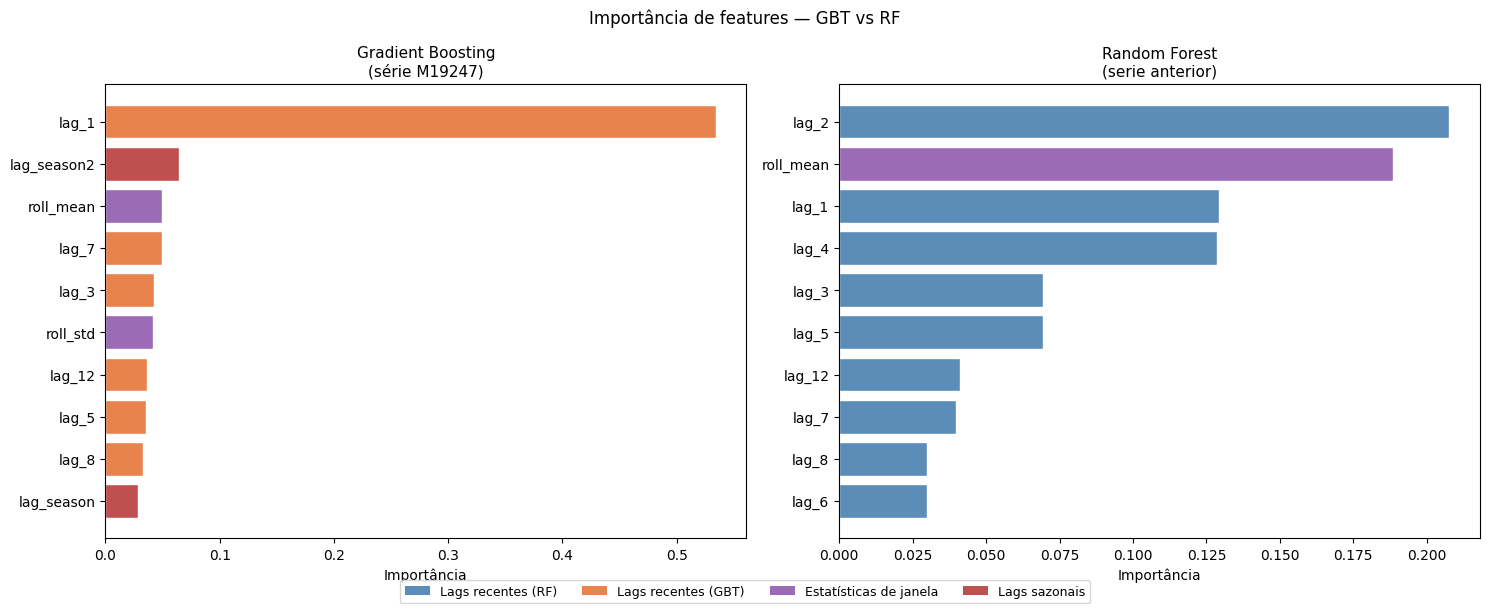

Figura salva em results/


In [12]:
# Gráfico comparativo de importâncias RF vs GBT
rf_imp_path = RESULT_DIR / 'rf_feature_importance_example.csv'

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (imp_data, title, color) in zip(axes, [
    (imp_gbt_df, f'Gradient Boosting\n(série {ex_uid_gbt})', '#E8834E'),
    (imp_gbt_df, 'GBT — top features', '#2E8B57'),   # placeholder se RF não disponível
]):
    top10 = imp_data.head(10)
    bar_colors = ['#C05050' if 'season' in f else
                  '#9B6BB5' if 'roll'   in f else
                  color
                  for f in top10['feature']]
    ax.barh(top10['feature'], top10['importance'],
            color=bar_colors, edgecolor='white')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Importância')
    ax.invert_yaxis()
    break   # só plota GBT — RF vem do arquivo

# Se tiver RF disponível, plota lado a lado
if rf_imp_path.exists():
    rf_imp = pd.read_csv(rf_imp_path).sort_values('importance', ascending=False)
    top10_rf = rf_imp.head(10)
    bar_colors_rf = ['#C05050' if 'season' in f else
                     '#9B6BB5' if 'roll'   in f else
                     '#5B8DB8'
                     for f in top10_rf['feature']]
    axes[1].barh(top10_rf['feature'], top10_rf['importance'],
                 color=bar_colors_rf, edgecolor='white')
    axes[1].set_title('Random Forest\n(serie anterior)', fontsize=11)
    axes[1].set_xlabel('Importância')
    axes[1].invert_yaxis()
else:
    axes[1].set_visible(False)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#5B8DB8', label='Lags recentes (RF)'),
    Patch(facecolor='#E8834E', label='Lags recentes (GBT)'),
    Patch(facecolor='#9B6BB5', label='Estatísticas de janela'),
    Patch(facecolor='#C05050', label='Lags sazonais'),
]
fig.legend(handles=legend_elements, loc='lower center',
           ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.02))

plt.suptitle('Importância de features — GBT vs RF', fontsize=12)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_gbt_vs_rf_importancia.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva em results/')

## 10. Boxplot comparativo acumulado

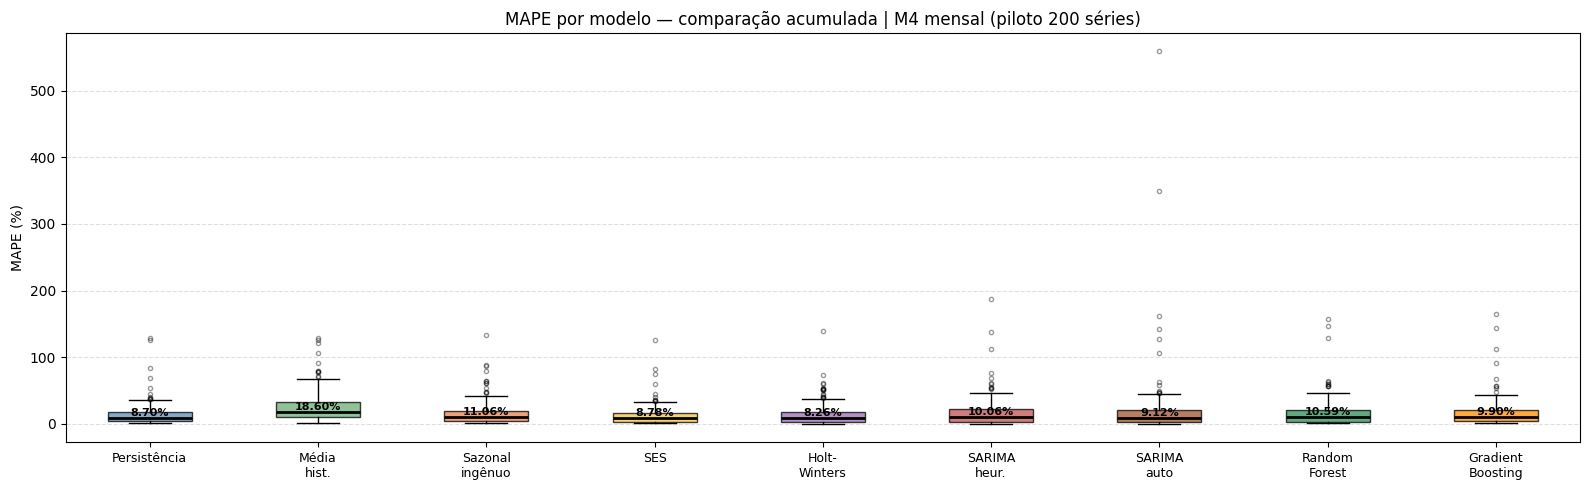

In [13]:
dfs = []
for fname, model_col in [
    ('results_nb02_by_series.csv',             None),
    ('results_ses_by_series.csv',              'ses'),
    ('results_sarima_heuristic_by_series.csv', 'sarima_heuristic'),
    ('results_sarima_auto_by_series.csv',      'sarima_auto'),
    ('results_rf_by_series.csv',               'random_forest'),
]:
    path = RESULT_DIR / fname
    if path.exists():
        df = pd.read_csv(path)
        if 'model' not in df.columns and model_col:
            df['model'] = model_col
        dfs.append(df)

gbt_plot = by_series_gbt.copy()
gbt_plot['model'] = 'gbt'
dfs.append(gbt_plot)
all_df = pd.concat(dfs, ignore_index=True)

order_plot = ['persistence','mean','seasonal_naive','ses',
              'holt_winters','sarima_heuristic','sarima_auto',
              'random_forest','gbt']
name_map   = {
    'persistence'     : 'Persistência',
    'mean'            : 'Média\nhist.',
    'seasonal_naive'  : 'Sazonal\ningênuo',
    'ses'             : 'SES',
    'holt_winters'    : 'Holt-\nWinters',
    'sarima_heuristic': 'SARIMA\nheur.',
    'sarima_auto'     : 'SARIMA\nauto',
    'random_forest'   : 'Random\nForest',
    'gbt'             : 'Gradient\nBoosting',
}
colors_plot = ['#5B8DB8','#6BAE75','#E8834E','#F5C242',
               '#9B6BB5','#C05050','#A0522D','#2E8B57','#FF8C00']

order_present = [m for m in order_plot if m in all_df['model'].unique()]
data_list     = [all_df[all_df['model']==m]['mape'].dropna() for m in order_present]

fig, ax = plt.subplots(figsize=(16, 5))
bp = ax.boxplot(
    data_list, patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.4)
)
for patch, color in zip(bp['boxes'], colors_plot[:len(order_present)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xticks(range(1, len(order_present)+1))
ax.set_xticklabels([name_map[m] for m in order_present], fontsize=9)
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE por modelo — comparação acumulada | M4 mensal (piloto 200 séries)')
ax.grid(axis='y', linestyle='--', alpha=0.4)
for i, d in enumerate(data_list):
    ax.text(i+1, d.median(), f'{d.median():.2f}%',
            ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_mape_acumulado_nb06.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Salvando artefatos

In [14]:
results_gbt.to_csv(RESULT_DIR / 'results_gbt_by_window.csv', index=False)
gbt_plot.to_csv(RESULT_DIR / 'results_gbt_by_series.csv', index=False)
imp_gbt_df.to_csv(RESULT_DIR / 'gbt_feature_importance_example.csv', index=False)

run_log = {
    'timestamp'    : datetime.now().isoformat(),
    'notebook'     : '06_gradient_boosting',
    'model'        : 'gbt',
    'n_lags'       : N_LAGS,
    'n_estimators' : N_ESTIMATORS,
    'learning_rate': LEARNING_RATE,
    'max_depth'    : MAX_DEPTH,
    'subsample'    : SUBSAMPLE,
    'dataset'      : 'M4_Monthly',
    'pilot_n'      : PILOT_N,
    'seed'         : SEED,
    'horizon_H'    : H,
    'n_ok'         : int(ok_n),
    'n_errors'     : int(err_n),
    'taxa_sucesso' : round(100*ok_n/(ok_n+err_n+skip_n), 2),
    'mape_median'  : round(float(by_series_gbt['mape'].median()), 4),
    'mae_median'   : round(float(by_series_gbt['mae'].median()),  4),
    'r2_median'    : round(float(by_series_gbt['r2'].median()),   4),
    'time_median_s': round(float(by_series_gbt['exec_time_s'].median()), 4),
}

with open(RESULT_DIR / 'run_log_gbt.json', 'w') as f:
    json.dump(run_log, f, indent=2)

print('Artefatos salvos:')
print('  results_gbt_by_window.csv')
print('  results_gbt_by_series.csv')
print('  gbt_feature_importance_example.csv')
print('  run_log_gbt.json')
print()
print(json.dumps(run_log, indent=2))

Artefatos salvos:
  results_gbt_by_window.csv
  results_gbt_by_series.csv
  gbt_feature_importance_example.csv
  run_log_gbt.json

{
  "timestamp": "2026-05-23T11:40:02.235150",
  "notebook": "06_gradient_boosting",
  "model": "gbt",
  "n_lags": 12,
  "n_estimators": 100,
  "learning_rate": 0.1,
  "max_depth": 3,
  "subsample": 0.8,
  "dataset": "M4_Monthly",
  "pilot_n": 200,
  "seed": 42,
  "horizon_H": 18,
  "n_ok": 600,
  "n_errors": 0,
  "taxa_sucesso": 100.0,
  "mape_median": 9.9031,
  "mae_median": 321.6768,
  "r2_median": -1.1837,
  "time_median_s": 0.0477
}


## 12. Resumo e próximos passos

---

### Panorama da família de árvores

| | Random Forest | Gradient Boosting |
|---|---|---|
| Estratégia | Paralela | Sequencial |
| Velocidade | Mais rápido | Mais lento |
| Tendência ao overfitting | Menor | Maior (controlado por learning_rate) |
| Importância de features | Impurity nativa | Impurity nativa |
| Compatível com SHAP | Sim (TreeSHAP) | Sim (TreeSHAP) |

---

### Próximo notebook: `07_svr.ipynb`
- Support Vector Regression — margem de generalização explícita
- Mesma engenharia de features para comparação justa
- Candidato forte para séries curtas (seção 2.4 da dissertação)